# Three-model comparison (no cache, tunable data)

Same unified-metrics methodology as `unified_metrics_comparison.ipynb`, trimmed to **three models**:

1. **SANOS KF** (`personal/SANOS_KF/sanos_kf.py`, `run_sanos_kf`) — online EKF on the exact
   tridiagonal SANOS DLV² density, run **with and without smoothing** (`cfg.smoothing`; smoothing =
   paper §3.1 production map, each density node blurred by a lognormal of variance `v = η·V_ATM`).
2. **KF on SVI** (the "spline" surface KF — 5-param Gatheral SVI slice).
3. **KF single-strike (1 s batches)** — per-strike random-walk EKF, one batch update per 1 s window.

**No caching.** All data is loaded live from `MassiveClient` + the tickers CSV, so the data
knobs in the CONFIG cell (`MIN_TRADES`, `TRADE_DATE`, puts/calls subset) take effect on a re-run.
Every model is scored in undiscounted **call** space (C/df) via `unified_metrics.evaluate`.

In [1]:
import sys
from pathlib import Path


def _find_root(start: Path) -> Path:
    for d in (start, *start.parents):
        if (d / "pyproject.toml").exists() and (d / "quantdata").is_dir():
            return d
    raise RuntimeError(f"quant_data project root not found above {start}")


PROJECT_ROOT = _find_root(Path.cwd().resolve())
for p in (
    PROJECT_ROOT,
    PROJECT_ROOT / "personal" / "shared_functions",
    PROJECT_ROOT / "personal" / "SANOS_KF",
    PROJECT_ROOT / "personal" / "Kalman_filter_spline",
):
    p = str(p)
    if p not in sys.path:
        sys.path.insert(0, p)

from datetime import date

import numpy as np
import pandas as pd
import polars as pl

import personal.Kalman_filter_spline.surface_model as sm
import personal.shared_functions.unified_metrics as um
from personal.Kalman_filter_spline.surface_kalman_filters import (
    build_iv_observations,
    run_spline_surface_kalman,
)
from personal.SANOS_KF.sanos_kf import SanosKFConfig, run_sanos_kf
from personal.shared_functions.kalman_filters import build_iv_surface
from quantdata.massive.client import MassiveClient

rows = []  # one metric dict per model -> um.comparison_table at the end
eval_tables = {}  # model_name -> standard eval table (for the NSE-vs-time warm-up plot)

/Users/elie/Documents/GitHub/quant_data/quantdata/__init__.py:212: UserWarning: Using cache mode 'on' as specified in environment variable QUANTDATA_CACHE_MODE.


## CONFIG

Everything tunable lives here. Re-run from this cell down after changing a knob.

In [2]:
# ── data knobs (no caching — these take effect on re-run) ──
TRADE_DATE = date(2024, 1, 3)
TICKER = "SPY"
MIN_TRADES = 0  # min trade_count per option ticker to include
PUTS_ONLY, CALLS_ONLY = True, False
# Single subset switch reused by every model so the comparison is apples-to-apples.
EVAL_IS_CALL = CALLS_ONLY if (CALLS_ONLY or PUTS_ONLY) else None  # None => calls AND puts

# ── evaluation window ──
# Exclude the first WARMUP_MIN minutes from scoring so every model is judged after its
# filter has converged (the bucket plot in the "Warm-up" section shows convergence in
# ~5-15 min for SANOS / single-strike). All four models use the same cutoff, so the
# comparison stays apples-to-apples. Set to 0 to score the whole day.
WARMUP_MIN = 30

# ── SANOS KF (run_sanos_kf) hyperparameters ──
# These match sweep_params.BASE + the best point of quick_sweep_free_sigma.py
# (ho_nse_med~0.45, mean~0.55 on SPY 2024-01-03). The grid params below are NOT the
# SanosKFConfig defaults (n_anchors=20, k_min=-0.20, k_max=0.15) — those defaults give
# a coarse, clipped strike grid and a much worse held-out fit, so set them explicitly.
SANOS_N_ANCHORS = 300  # cap on strike-aligned interior nodes (default 20 is far too coarse)
SANOS_K_MIN = -0.60  # log-moneyness grid lo — must cover the put wing (data ~ -0.56)
SANOS_K_MAX = 0.10  # log-moneyness grid hi (data ~ +0.07)
SANOS_BATCH_S = 1.0  # window width (seconds): one predict + one batch update per window
SANOS_Q_SCALE_DLV = 1e-3  # process noise scale for net DLV^2 per trading day
SANOS_P0_SCALE = 0.001  # initial covariance diagonal scale
SANOS_ELL = 5.0  # RBF correlation length in DOLLARS
SANOS_SIGMA_INIT = 0.01  # initial net DLV^2 (flat)
SANOS_CORRELATED = True
ETA = 0.06  # SANOS smoothness for the "with smoothing" run (v = ETA * V_ATM); best in sweep

# ── KF-on-SVI (spline) hyperparameters ──
SPLINE_Q_SCALE, SPLINE_P0_SCALE, SPLINE_BATCH_S = 1e-8, 1e-4, 1.0

# ── KF single-strike (1 s batch) hyperparameters ──
SINGLE_BATCH_S, SINGLE_Q_SCALE = 1.0, 4.1e-5

## Load raw data (shared by all models)

Fetched once from `MassiveClient` + the tickers CSV; `build_iv_observations` produces the IV-annotated quote/trade frames used by the SANOS and spline models.

In [3]:
client = MassiveClient()
df_tickers = pl.read_csv(PROJECT_ROOT / "personal" / f"spy_options_tickers_{TRADE_DATE}.csv")
df_spy = client.fetch_trades(TICKER, TRADE_DATE)

# IV-annotated quotes/trades (puts AND calls; subset is applied per model below).
df_quotes, df_trades = build_iv_observations(df_tickers, TRADE_DATE, df_spy, min_trades=MIN_TRADES)
print(
    f"build_iv_observations: {df_quotes.height:,} quote rows, "
    f"{df_quotes['strike'].n_unique()} strikes"
)

# Shared scoring origin (epoch seconds) — the first quote of the day. `ts_ns` is a polars
# Datetime, so convert to epoch-nanoseconds (the same convention the eval tables use via
# pandas .astype("int64")) and floor to seconds. Every model's eval-table `ts` is in epoch
# seconds (1 s batches), so warm-up exclusion is `ts >= DAY_OPEN_TS + WARMUP_MIN*60`.
_ts = df_quotes["ts_ns"]
_ts_ns = _ts.dt.epoch("ns") if isinstance(_ts.dtype, pl.Datetime) else _ts
DAY_OPEN_TS = int(_ts_ns.min() // 1_000_000_000)


def apply_warmup(tbl):
    """Drop snapshots in the first WARMUP_MIN minutes so each model is scored only after
    its filter has converged. Returns the table unchanged when WARMUP_MIN == 0. The full
    (un-trimmed) table is what gets stored in `eval_tables` for the warm-up plot — this
    trim affects scoring only."""
    if not WARMUP_MIN:
        return tbl
    return tbl[tbl["ts"] >= DAY_OPEN_TS + WARMUP_MIN * 60]

Skipping O:SPY240105C00388000: no matched trades
Skipping O:SPY240105C00424000: no matched trades
Skipping O:SPY240105C00425000: no matched trades
Skipping O:SPY240105C00441000: no matched trades
Skipping O:SPY240105C00443000: no matched trades
Skipping O:SPY240105C00453000: no matched trades
Skipping O:SPY240105C00481000: 46 bad quotes
Skipping O:SPY240105C00482000: 64 bad quotes
Skipping O:SPY240105C00483000: 842 bad quotes
Skipping O:SPY240105C00484000: 2129 bad quotes
Skipping O:SPY240105C00485000: 3888 bad quotes
Skipping O:SPY240105C00486000: 4860 bad quotes
Skipping O:SPY240105C00487000: 1630 bad quotes
Skipping O:SPY240105C00488000: 136 bad quotes
Skipping O:SPY240105C00489000: 130 bad quotes
Skipping O:SPY240105C00490000: 218 bad quotes
Skipping O:SPY240105C00491000: 370 bad quotes
Skipping O:SPY240105C00492000: 341 bad quotes
Skipping O:SPY240105C00493000: 342 bad quotes
Skipping O:SPY240105C00494000: 290 bad quotes
Skipping O:SPY240105C00495000: 202 bad quotes
Skipping O:SPY

## 1. SANOS KF — with and without smoothing

`run_sanos_kf` filters the exact tridiagonal SANOS DLV² density online, one batch update per `SANOS_BATCH_S` window (held-out prior = previous window's posterior). The subset is selected via `cfg.puts_only`/`cfg.calls_only` (so the ATM-variance estimate for smoothing can still see both wings). We run it twice: `smoothing=False` (intrinsic) and `smoothing=True` (η·V_ATM).

In [4]:
def sanos_kf_eval_table(df_res, batch_s):
    """Standard eval table from run_sanos_kf output. sanos_kf_price[_prior] are
    F-normalized calls C/(F·df) → multiply by F for call space C/df. Market mid/spread
    are PCP-converted to the same C/df space. One row per (window, strike) so the
    per-snapshot Breeden-Litzenberger negative mass in um.evaluate is clean.
    (Same methodology as sweep_params._run_one, so numbers match the sweep.)"""
    q = df_res.to_pandas().dropna(subset=["sanos_kf_price", "sanos_kf_price_prior"])
    F = q["forward"].to_numpy(float)
    K = q["strike"].to_numpy(float)
    ic = q["is_call"].to_numpy(bool)
    dfac = q["discount_factor"].to_numpy(float) if "discount_factor" in q else np.ones(len(q))
    dfac = np.where(np.isfinite(dfac) & (dfac > 0), dfac, 1.0)
    to_call = lambda p: np.where(ic, p, p + F - K)  # native undiscounted → call space (PCP)
    bid = q["bid_price"].to_numpy(float)
    ask = q["ask_price"].to_numpy(float)
    out = pd.DataFrame(
        {
            "ts": (q["ts_ns"].astype("int64") // int(batch_s * 1e9)).to_numpy(),
            "strike": K,
            "forward": F,
            "mid_call": to_call(0.5 * (bid + ask) / dfac),
            "half_spread": np.maximum(0.5 * (ask - bid) / dfac, 1e-10),
            "prior_call": q["sanos_kf_price_prior"].to_numpy(float) * F,
            "post_call": q["sanos_kf_price"].to_numpy(float) * F,
        }
    )
    return out.drop_duplicates(subset=["ts", "strike"], keep="last")


def run_sanos(smoothing, name):
    cfg = SanosKFConfig(
        n_anchors=SANOS_N_ANCHORS,
        k_min=SANOS_K_MIN,
        k_max=SANOS_K_MAX,
        batch_seconds=SANOS_BATCH_S,
        smoothing=smoothing,
        eta=ETA,
        Q_scale_dlv=SANOS_Q_SCALE_DLV,
        P0_scale=SANOS_P0_SCALE,
        ell=SANOS_ELL,
        Sigma_init=SANOS_SIGMA_INIT,
        correlated=SANOS_CORRELATED,
        puts_only=PUTS_ONLY,
        calls_only=CALLS_ONLY,
    )
    df_res, _ = run_sanos_kf(df_quotes, df_trades, cfg)
    tbl = sanos_kf_eval_table(df_res, SANOS_BATCH_S)
    eval_tables[name] = tbl  # full-day table for the NSE-vs-time warm-up plot
    m = um.evaluate(apply_warmup(tbl), model_name=name)  # score post-warm-up only
    rows.append(m)
    return m


m_sanos_ns = run_sanos(smoothing=False, name="SANOS KF (no smoothing)")
m_sanos_s = run_sanos(smoothing=True, name=f"SANOS KF (smoothing eta={ETA})")
pd.DataFrame([m_sanos_ns, m_sanos_s])

,model,ho_nse_mean,ho_nse_med,ho_nse_std,is_nse_mean,is_nse_med,is_nse_std,ho_rmse_mean,ho_rmse_med,ho_rmse_std,...,is_rmse_med,is_rmse_std,ho_out_pct_mean,ho_out_pct_med,is_out_pct_mean,is_out_pct_med,neg_mass_mean,neg_mass_med,arb_frac,n_snapshots
0,SANOS KF (no smoothing),0.545601,0.474257,0.345527,0.453099,0.385471,0.312144,0.034065,0.028480,0.030936,...,0.028218,0.031136,13.637020,11.111111,9.438384,4.545455,-3.912758e-07,0.0,0.001266,22320
1,SANOS KF (smoothing eta=0.06),0.521881,0.445780,0.348648,0.430371,0.357148,0.316159,0.034545,0.029157,0.032004,...,0.029124,0.032196,12.600829,9.090909,8.739406,0.000000,-3.941286e-07,0.0,0.001266,22320


## 2. KF on SVI (spline surface)

5-param Gatheral SVI slice, fit & evaluated in 1 s batches (one time-proportional predict + one batch update per window). `prior_price` = pre-update (held-out) price, `post_price` = posterior.

In [5]:
df_quotes_iv = df_quotes
df_trades_iv = df_trades
if EVAL_IS_CALL is not None:  # same subset as the SANOS model
    df_quotes_iv = df_quotes_iv.filter(pl.col("is_call") == EVAL_IS_CALL)
    df_trades_iv = df_trades_iv.filter(pl.col("is_call") == EVAL_IS_CALL)

cfg_spline = sm.SurfaceModelConfig(
    model=sm.SVI_SLICE_MODEL,
    Q_scale=SPLINE_Q_SCALE,
    Q_structure="scaled_identity",
    P0_scale=SPLINE_P0_SCALE,
)

q_res, t_res, df_state = run_spline_surface_kalman(
    df_quotes_iv, df_trades_iv, cfg_spline, batch_seconds=SPLINE_BATCH_S
)
q = q_res.sort(["strike", "is_call", "ts_ns"]).to_pandas()
q["window"] = q["ts_ns"].astype("int64") // int(SPLINE_BATCH_S * 1e9)
snap = q.dropna(subset=["kalman_price_prior"])

df_spline = um.from_option_prices(
    ts=snap["window"],
    strike=snap["strike"],
    forward=snap["forward"],
    is_call=snap["is_call"],
    bid=snap["bid_price"],
    ask=snap["ask_price"],
    prior_price=snap["kalman_price_prior"],
    post_price=snap["kalman_price"],
    discount_factor=snap["discount_factor"] if "discount_factor" in snap else None,
)
# One row per (window, strike), keep last — same snapshot methodology as SANOS.
df_spline = df_spline.drop_duplicates(subset=["ts", "strike"], keep="last")

In [6]:
# Negative mass: reconstruct the SVI smile over a strike grid at sampled times.
state_pd = df_state.to_pandas().sort_values("ts_ns").reset_index(drop=True)
n_params = cfg_spline.n_params
theta_cols = [f"theta_{j}" for j in range(n_params)]
grid_K_nm = np.linspace(
    float(df_quotes_iv["strike"].min()), float(df_quotes_iv["strike"].max()), 41
)
n_snap = min(1000, len(state_pd))
state_samp = state_pd.iloc[np.linspace(0, len(state_pd) - 1, n_snap, dtype=int)].reset_index(
    drop=True
)
q_sorted = q.sort_values("ts_ns").reset_index(drop=True)
asof = np.clip(
    np.searchsorted(q_sorted["ts_ns"].values, state_samp["ts_ns"].values, "right") - 1,
    0,
    len(q_sorted) - 1,
)
F_vec, T_vec = q_sorted["forward"].values[asof], q_sorted["T"].values[asof]
thetas = state_samp[theta_cols].values
C_mat = np.full((n_snap, len(grid_K_nm)), np.nan)
for i in range(n_snap):
    th, F_i, T_i = thetas[i], F_vec[i], T_vec[i]
    if not (np.isfinite(th).all() and F_i > 0 and np.isfinite(F_i) and T_i > 0):
        continue
    ivs = np.array([cfg_spline.model.observe(th, np.log(k / F_i), T_i)[0] for k in grid_K_nm])
    C_mat[i] = um.bs_call_price(
        np.full(len(grid_K_nm), F_i), grid_K_nm, np.full(len(grid_K_nm), T_i), ivs
    )
valid = np.isfinite(C_mat).all(axis=1)
nm_spline = um.negative_mass_surface(grid_K_nm, C_mat[valid], F_vec[valid])

SPLINE_NAME = "KF on SVI (spline)"
eval_tables[SPLINE_NAME] = df_spline  # full-day table for the NSE-vs-time warm-up plot
# NSE/RMSE scored post-warm-up; neg_mass is the full-day arb summary (not warm-up sensitive).
m_spline = um.evaluate(apply_warmup(df_spline), model_name=SPLINE_NAME, neg_mass_values=nm_spline)
rows.append(m_spline)
m_spline

{'model': 'KF on SVI (spline)',
 'ho_nse_mean': 1.1424992834332948,
 'ho_nse_med': 0.9744854050277868,
 'ho_nse_std': 3.8323345299369462,
 'is_nse_mean': 0.9481546945675928,
 'is_nse_med': 0.8827437525611909,
 'is_nse_std': 3.338703825833425,
 'ho_rmse_mean': 0.10099169409117552,
 'ho_rmse_med': 0.10421066342660988,
 'ho_rmse_std': 0.07997052593366012,
 'is_rmse_mean': 0.0997844772329578,
 'is_rmse_med': 0.10395500478087281,
 'is_rmse_std': 0.07765665149049839,
 'ho_out_pct_mean': 42.09672051138037,
 'ho_out_pct_med': 42.857142857142854,
 'is_out_pct_mean': 36.761401701677144,
 'is_out_pct_med': 37.5,
 'neg_mass_mean': -0.0016954029086944519,
 'neg_mass_med': 0.0,
 'arb_frac': 0.408,
 'n_snapshots': 22320}

## 3. KF single-strike (1 s batches)

Per-strike random-walk EKF assimilated in 1 s windows (`build_iv_surface(..., batch_seconds=1.0)`). The held-out one-step-ahead prior is the **previous window's** posterior (no in-window leakage).

In [7]:
df_quotes_iv_b, df_trades_iv_b = build_iv_surface(
    df_tickers,
    TRADE_DATE,
    df_spy=df_spy,
    min_trades=MIN_TRADES,
    simple=False,
    batch_seconds=SINGLE_BATCH_S,
    q_scale=SINGLE_Q_SCALE,
    is_call_filter=EVAL_IS_CALL,
)
qb = df_quotes_iv_b.sort(["strike", "is_call", "ts_ns"]).to_pandas()
qb["window"] = qb["ts_ns"].astype("int64") // int(SINGLE_BATCH_S * 1e9)
# held-out prior = previous window's posterior price (representative = last quote in window)
_post_w = qb.groupby(["strike", "is_call", "window"], as_index=False).agg(
    _post_win=("kalman_price", "last")
)
_post_w["kalman_price_prior"] = _post_w.groupby(["strike", "is_call"])["_post_win"].shift(1)
qb = qb.merge(
    _post_w[["strike", "is_call", "window", "kalman_price_prior"]],
    on=["strike", "is_call", "window"],
    how="left",
)
qb = qb.dropna(subset=["kalman_price_prior"])
df_single = um.from_option_prices(
    ts=qb["window"],
    strike=qb["strike"],
    forward=qb["forward"],
    is_call=qb["is_call"],
    bid=qb["bid_price"],
    ask=qb["ask_price"],
    prior_price=qb["kalman_price_prior"],
    post_price=qb["kalman_price"],
    discount_factor=qb["discount_factor"] if "discount_factor" in qb else None,
)
# One row per (window, strike), keep last — same snapshot methodology as SANOS.
df_single = df_single.drop_duplicates(subset=["ts", "strike"], keep="last")

Skipping O:SPY240105C00388000: no matched trades
Skipping O:SPY240105C00424000: no matched trades
Skipping O:SPY240105C00425000: no matched trades
Skipping O:SPY240105C00441000: no matched trades
Skipping O:SPY240105C00443000: no matched trades
Skipping O:SPY240105C00453000: no matched trades
O:SPY240105C00469000: dropping 2 bad quotes (crossed×2 (first=2024-01-03 11:49:45.633413-05:00))
O:SPY240105C00472000: dropping 1 bad quotes (crossed×1 (first=2024-01-03 15:51:02.275318-05:00))
O:SPY240105C00473000: dropping 1 bad quotes (crossed×1 (first=2024-01-03 10:29:17.744517-05:00))
O:SPY240105C00474000: dropping 4 bad quotes (crossed×4 (first=2024-01-03 10:25:56.925706-05:00))
O:SPY240105C00475000: dropping 1 bad quotes (crossed×1 (first=2024-01-03 14:02:06.496803-05:00))
O:SPY240105C00477000: dropping 1 bad quotes (crossed×1 (first=2024-01-03 10:00:44.569057-05:00))
O:SPY240105C00481000: dropping 46 bad quotes (sub-tick bid×46 (first=2024-01-03 16:00:02.443177-05:00))
O:SPY240105C00482000

In [8]:
# Negative mass: asof-join post_call across strikes at sampled times, then BL.
puts_mask = ~qb["is_call"]
ds = df_single[df_single["ts"].isin(qb.loc[puts_mask, "window"])].copy()
uK = np.sort(ds["strike"].unique())
n_snap_s = min(500, ds["ts"].nunique())
ts_int = ds["ts"].astype(np.int64).values
snap_ts = np.linspace(ts_int.min(), ts_int.max(), n_snap_s, dtype=np.int64)
groups = {K: g.sort_values("ts").reset_index(drop=True) for K, g in ds.groupby("strike")}
ref = groups[uK[len(uK) // 2]]
ref_asof = np.clip(
    np.searchsorted(ref["ts"].astype(np.int64).values, snap_ts, "right") - 1, 0, len(ref) - 1
)
F_arr = ref["forward"].values[ref_asof]
C_s = np.full((n_snap_s, len(uK)), np.nan)
for j, Kj in enumerate(uK):
    g = groups[Kj]
    idx = np.clip(
        np.searchsorted(g["ts"].astype(np.int64).values, snap_ts, "right") - 1, 0, len(g) - 1
    )
    C_s[:, j] = g["post_call"].values[idx]
valid_s = np.isfinite(C_s).all(axis=1) & np.isfinite(F_arr)
nm_single = um.negative_mass_surface(uK, C_s[valid_s], F_arr[valid_s])

SINGLE_NAME = f"KF single-strike (1s batch, q={SINGLE_Q_SCALE})"
eval_tables[SINGLE_NAME] = df_single  # full-day table for the NSE-vs-time warm-up plot
# NSE/RMSE scored post-warm-up; neg_mass is the full-day arb summary (not warm-up sensitive).
m_single = um.evaluate(
    apply_warmup(df_single),
    model_name=SINGLE_NAME,
    neg_mass_values=nm_single,
)
rows.append(m_single)
m_single

{'model': 'KF single-strike (1s batch, q=4.1e-05)',
 'ho_nse_mean': 0.37487041838397,
 'ho_nse_med': 0.29992123194642556,
 'ho_nse_std': 0.2876661187081506,
 'is_nse_mean': 0.13188105193226007,
 'is_nse_med': 0.12371680254781685,
 'is_nse_std': 0.05610115396477786,
 'ho_rmse_mean': 0.012989219223434541,
 'ho_rmse_med': 0.00884271410781793,
 'ho_rmse_std': 0.014865642376987516,
 'is_rmse_mean': 0.00970093561926401,
 'is_rmse_med': 0.005303952537294981,
 'is_rmse_std': 0.01345342383773763,
 'ho_out_pct_mean': 11.209537611792188,
 'ho_out_pct_med': 8.333333333333332,
 'is_out_pct_mean': 0.5653484836312428,
 'is_out_pct_med': 0.0,
 'neg_mass_mean': -2.2776814047544347,
 'neg_mass_med': -2.1969970583203136,
 'arb_frac': 1.0,
 'n_snapshots': 22343}

## Comparison table

In [9]:
cmp = um.comparison_table(rows)
cmp

,ho_nse_mean,ho_nse_med,ho_nse_std,is_nse_mean,is_nse_med,is_nse_std,ho_rmse_mean,ho_rmse_med,ho_rmse_std,is_rmse_mean,is_rmse_med,is_rmse_std,ho_out_pct_mean,ho_out_pct_med,is_out_pct_mean,is_out_pct_med,neg_mass_mean,neg_mass_med,arb_frac,n_snapshots
model,,,,,,,,,,,,,,,,,,,,
SANOS KF (no smoothing),0.545601,0.474257,0.345527,0.453099,0.385471,0.312144,0.034065,0.028480,0.030936,0.033624,0.028218,0.031136,13.637020,11.111111,9.438384,4.545455,-3.912758e-07,0.000000,0.001266,22320
SANOS KF (smoothing eta=0.06),0.521881,0.445780,0.348648,0.430371,0.357148,0.316159,0.034545,0.029157,0.032004,0.034104,0.029124,0.032196,12.600829,9.090909,8.739406,0.000000,-3.941286e-07,0.000000,0.001266,22320
KF on SVI (spline),1.142499,0.974485,3.832335,0.948155,0.882744,3.338704,0.100992,0.104211,0.079971,0.099784,0.103955,0.077657,42.096721,42.857143,36.761402,37.500000,-1.695403e-03,0.000000,0.408000,22320
"KF single-strike (1s batch, q=4.1e-05)",0.374870,0.299921,0.287666,0.131881,0.123717,0.056101,0.012989,0.008843,0.014866,0.009701,0.005304,0.013453,11.209538,8.333333,0.565348,0.000000,-2.277681e+00,-2.196997,1.000000,22343


In [10]:
cmp.sort_values("ho_nse_mean").to_csv(
    PROJECT_ROOT / "personal" / f"three_model_comparison_{TRADE_DATE}.csv", index=True
)

## Warm-up — held-out NSE vs time

Per-model held-out NSE as a function of intraday time, to *see the convergence elbow*: the
filters start from a flat/poorly-informed prior and need quotes to assimilate before the held-out
error settles. Everything left of the elbow is warm-up and arguably shouldn't be scored.

Methodology is identical to `um.evaluate`'s held-out aggregation — for each 1 s snapshot,
`mean( |prior_call − mid_call| / half_spread )` over that snapshot's strikes — then those
per-snapshot values are **medianed into 1-minute bins** (median = robust to the spline's outliers).
All models share one `t0` (first snapshot ≈ market open) so the x-axes line up.

The printed `warm-up` per model is a crude convergence estimate: the first minute after which the
per-minute curve stays within 1.15× of the day's plateau (median of the last 120 min). Use the plot
to sanity-check it and pick a single shared cutoff (the dashed line at 90 min is just a reference).

median held-out NSE by minutes-since-open bucket:
                                         0-5m  5-15m  15-30m  30-60m  60-90m   90m+
SANOS KF (no smoothing)                 0.630  0.507   0.531   0.536   0.490  0.460
SANOS KF (smoothing eta=0.06)           0.621  0.484   0.491   0.501   0.460  0.432
KF on SVI (spline)                      1.090  1.187   1.199   1.099   1.127  0.935
KF single-strike (1s batch, q=4.1e-05)  0.385  0.382   0.339   0.353   0.317  0.285

(scoring excludes the first WARMUP_MIN=30 min — shaded band below)

warm-up (first minute the SMOOTHED curve reaches 1.15x of the day's plateau):
  SANOS KF (no smoothing)                    ~    2 min   (plateau HO-NSE 0.482)
  SANOS KF (smoothing eta=0.06)              ~    3 min   (plateau HO-NSE 0.454)
  KF on SVI (spline)                         ~  214 min   (plateau HO-NSE 0.768)
  KF single-strike (1s batch, q=4.1e-05)     ~    8 min   (plateau HO-NSE 0.331)


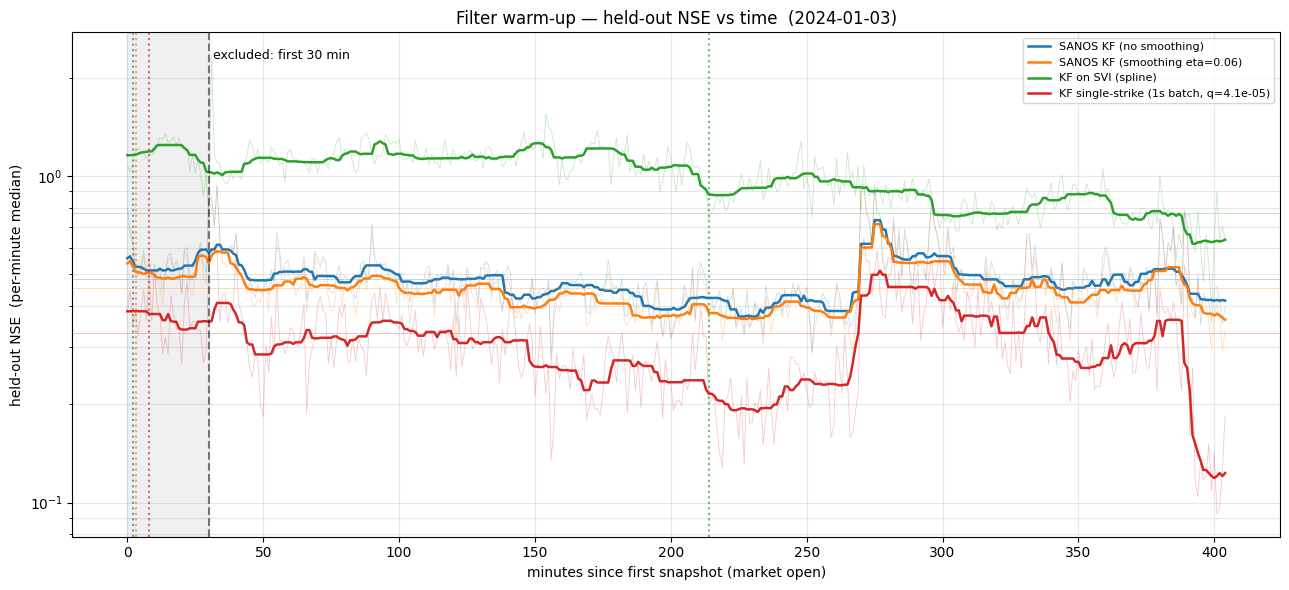

In [11]:
import matplotlib.pyplot as plt


def ho_nse_per_snapshot(tbl):
    """Per-snapshot held-out NSE, exactly um.evaluate's HO aggregation but kept as a
    time series: for each ts, mean over its strikes of |prior_call - mid_call| / half_spread.
    Returns a Series indexed by ts (integer seconds since epoch, since all batches are 1 s)."""
    hs = tbl["half_spread"].to_numpy(float)
    hs = np.where(np.isfinite(hs) & (hs > 0), hs, np.nan)
    ho = np.abs(tbl["prior_call"].to_numpy(float) - tbl["mid_call"].to_numpy(float)) / hs
    return pd.Series(ho, index=tbl["ts"].to_numpy()).groupby(level=0).mean().dropna()


# shared origin so every model is on the same "minutes since first snapshot" axis.
# DAY_OPEN_TS (from the load cell) is the same t0 used by apply_warmup, so the shaded
# warm-up band below lines up exactly with what's excluded from scoring.
_series = {name: ho_nse_per_snapshot(tbl) for name, tbl in eval_tables.items()}
t0 = DAY_OPEN_TS


def per_minute(s):
    """Median per-snapshot HO-NSE within each 1-minute bin -> (minutes, Series)."""
    minute = (s.index.to_numpy(np.int64) - t0) // 60
    g = pd.Series(s.to_numpy(), index=minute).groupby(level=0).median()
    return g.index.to_numpy(float), g.to_numpy(float)


def smooth(nse, w=15):
    """Centered rolling median over `w` minutes — the trend through the intraday noise."""
    return pd.Series(nse).rolling(w, min_periods=max(3, w // 3), center=True).median().to_numpy()


def warmup_minute(mins, nse, plateau_window=120, tol=1.15):
    """First minute the *smoothed* curve drops to within tol x the day's plateau
    (median of the last `plateau_window` min). First crossing — not 'stays below
    forever' — so a single late-day spike no longer pushes it to the close.
    A value near 0 means there is effectively no warm-up (already converged)."""
    sm = smooth(nse)
    plateau = np.nanmedian(sm[mins >= mins.max() - plateau_window])
    below = sm <= tol * plateau
    return (float(mins[np.argmax(below)]) if below.any() else np.nan), float(plateau)


# ── median HO-NSE by minutes-since-open bucket — the clearest convergence read ──
# If the first buckets are >> the 90m+ bucket and decreasing, the filter warms up
# (and the warm-up length is visible). If they're already ~ the 90m+ level, there is
# no meaningful warm-up — the early "noise" is just the steady-state error.
_buckets = [(0, 5), (5, 15), (15, 30), (30, 60), (60, 90), (90, 10**9)]
_labels = [f"{a}-{b}m" if b < 10**9 else f"{a}m+" for a, b in _buckets]
bucket_rows = {}
for name, s in _series.items():
    mins, nse = per_minute(s)
    bucket_rows[name] = [
        np.nanmedian(nse[(mins >= a) & (mins < b)]) if ((mins >= a) & (mins < b)).any() else np.nan
        for a, b in _buckets
    ]
bucket_tbl = pd.DataFrame(bucket_rows, index=_labels).T
print("median held-out NSE by minutes-since-open bucket:")
print(bucket_tbl.round(3).to_string())
print(f"\n(scoring excludes the first WARMUP_MIN={WARMUP_MIN} min — shaded band below)\n")

# ── plot: per-minute curve (faint) + smoothed trend (bold) + warm-up marker ──
fig, ax = plt.subplots(figsize=(13, 6))
print("warm-up (first minute the SMOOTHED curve reaches 1.15x of the day's plateau):")
for name, s in _series.items():
    mins, nse = per_minute(s)
    (line,) = ax.plot(mins, nse, lw=0.6, alpha=0.25)
    ax.plot(mins, smooth(nse), lw=1.8, color=line.get_color(), label=name)
    wm, plateau = warmup_minute(mins, nse)
    ax.axhline(plateau, color=line.get_color(), ls="-", lw=0.5, alpha=0.4)
    if np.isfinite(wm):
        ax.axvline(wm, color=line.get_color(), ls=":", alpha=0.7)
    print(f"  {name:42s} ~{wm:>5.0f} min   (plateau HO-NSE {plateau:.3f})")

if WARMUP_MIN:  # grey band = excluded from scoring (apply_warmup uses the same t0)
    ax.axvspan(0, WARMUP_MIN, color="grey", alpha=0.12)
    ax.axvline(WARMUP_MIN, color="k", ls="--", alpha=0.5)
    ax.text(
        WARMUP_MIN, ax.get_ylim()[1], f" excluded: first {WARMUP_MIN} min", va="top", fontsize=9
    )
ax.set_xlabel("minutes since first snapshot (market open)")
ax.set_ylabel("held-out NSE  (per-minute median)")
ax.set_yscale("log")
ax.set_title(f"Filter warm-up — held-out NSE vs time  ({TRADE_DATE})")
ax.legend(fontsize=8, loc="upper right")
ax.grid(alpha=0.3, which="both")
plt.tight_layout()
plt.show()

## Robustness — RMSE and out-of-band % vs time

The NSE-vs-time drift before 14:00 is suspected to be the *denominator* (spreads tightening
through the morning), not the models improving. These two views remove / invert that dependence:

- **RMSE** = per-snapshot `sqrt(mean((prior_call − mid_call)²))` in **price units (C/df)** —
  the pricing error itself, with **no spread in it**. If RMSE is ~flat while NSE drifts down, the
  NSE drift is a spread artifact. If RMSE *also* slopes down, there's genuine intraday improvement.

- **Out-of-band %** = per-snapshot `100·mean(|prior_call − mid_call| > half_spread)` — the share of
  strikes priced outside the bid-ask band. This *inverts* the spread dependence: as spreads tighten
  the band narrows, so a constant error pushes out-pct **up**. So if out-pct is flat or rising while
  NSE falls, that's direct evidence the NSE fall is spreads, not accuracy ("kinda" robust — it still
  moves with error too, just in the opposite spread direction).

Both reuse the same per-snapshot → per-minute-median machinery and `t0` as the NSE plot. The purple
dashed line marks 270 min ≈ 14:00 ET (December FOMC minutes release).

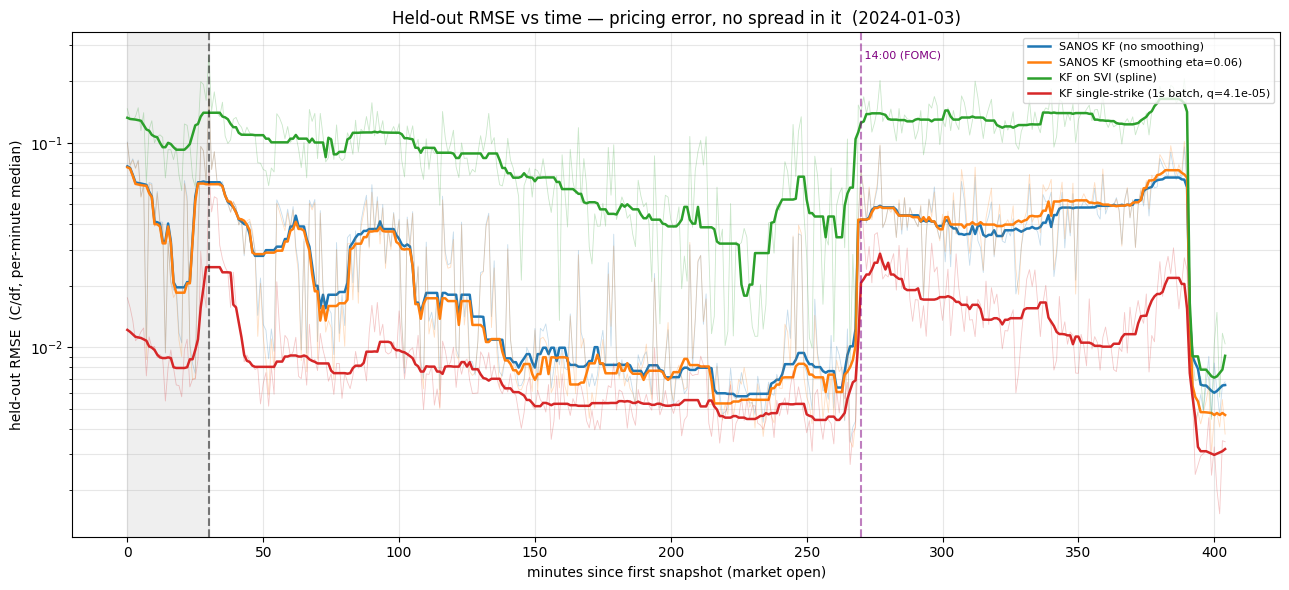

In [12]:
def per_snapshot_metric(tbl, kind):
    """Per-snapshot held-out metric as a ts-indexed Series, matching um.evaluate's
    per-snapshot aggregation (mask = finite prior/mid/half_spread):
       'rmse' -> sqrt(mean((prior_call - mid_call)^2))         [price units, C/df]
       'out'  -> 100 * mean(|prior_call - mid_call| > half_spread)  [% strikes outside band]
    """
    prior = tbl["prior_call"].to_numpy(float)
    mid = tbl["mid_call"].to_numpy(float)
    hs = tbl["half_spread"].to_numpy(float)
    hs = np.where(np.isfinite(hs) & (hs > 0), hs, np.nan)
    mask = np.isfinite(prior) & np.isfinite(mid) & np.isfinite(hs)
    err = prior - mid
    if kind == "rmse":
        col = np.where(mask, err**2, np.nan)
        g = pd.Series(col, index=tbl["ts"].to_numpy()).groupby(level=0).mean().dropna()
        return np.sqrt(g)
    if kind == "out":
        col = np.where(mask, (np.abs(err) > hs).astype(float), np.nan)
        return pd.Series(col, index=tbl["ts"].to_numpy()).groupby(level=0).mean().dropna() * 100.0
    raise ValueError(f"unknown kind {kind!r}")


def plot_metric_vs_time(kind, ylabel, title, logy=False):
    """Per-minute median of a per-snapshot held-out metric, faint raw + bold smoothed,
    same t0 / warm-up band as the NSE plot. Purple line = 14:00 ET (FOMC minutes)."""
    fig, ax = plt.subplots(figsize=(13, 6))
    for name, tbl in eval_tables.items():
        s = per_snapshot_metric(tbl, kind)
        mins, val = per_minute(s)
        (line,) = ax.plot(mins, val, lw=0.6, alpha=0.25)
        ax.plot(mins, smooth(val), lw=1.8, color=line.get_color(), label=name)
    if WARMUP_MIN:
        ax.axvspan(0, WARMUP_MIN, color="grey", alpha=0.12)
        ax.axvline(WARMUP_MIN, color="k", ls="--", alpha=0.5)
    ax.axvline(270, color="purple", ls="--", alpha=0.5)  # ~14:00 ET — Dec FOMC minutes
    ax.text(270, ax.get_ylim()[1], " 14:00 (FOMC)", va="top", fontsize=8, color="purple")
    ax.set_xlabel("minutes since first snapshot (market open)")
    ax.set_ylabel(ylabel)
    if logy:
        ax.set_yscale("log")
    ax.set_title(f"{title}  ({TRADE_DATE})")
    ax.legend(fontsize=8, loc="upper right")
    ax.grid(alpha=0.3, which="both")
    plt.tight_layout()
    plt.show()


plot_metric_vs_time(
    "rmse",
    "held-out RMSE  (C/df, per-minute median)",
    "Held-out RMSE vs time — pricing error, no spread in it",
    logy=True,
)

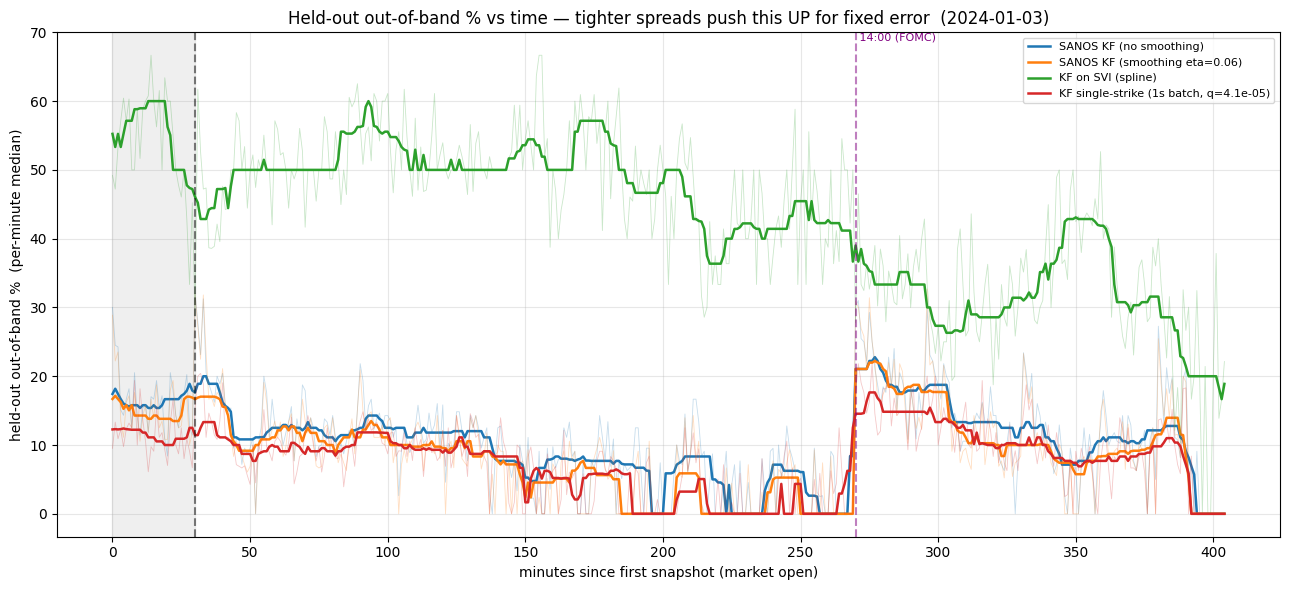

In [13]:
plot_metric_vs_time(
    "out",
    "held-out out-of-band %  (per-minute median)",
    "Held-out out-of-band % vs time — tighter spreads push this UP for fixed error",
    logy=False,
)

In [19]:
np.argmax(strike_counts)

np.int64(0)

In [ ]:
import plotly.graph_objects as go
from plotly.subplots import make_subplots
from scipy.optimize import brentq

IDX = 0  # change to browse snapshots

tbl_ssvi = eval_tables[SPLINE_NAME]
tbl_indiv = eval_tables[SINGLE_NAME]

ts_common = sorted(set(tbl_ssvi["ts"].unique()) & set(tbl_indiv["ts"].unique()))
ts_pick = ts_common[IDX]

snap_ssvi = tbl_ssvi[tbl_ssvi["ts"] == ts_pick].sort_values("strike")
snap_indiv = tbl_indiv[tbl_indiv["ts"] == ts_pick].sort_values("strike")

# ── reconstruct SVI smooth IV curve at ts_pick ──
ts_pick_ns = ts_pick * int(SPLINE_BATCH_S * 1e9)
state_ts_ns = state_pd["ts_ns"].to_numpy(np.int64)
idx_state = np.argmin(np.abs(state_ts_ns - ts_pick_ns))
th = state_pd[theta_cols].values[idx_state]

idx_q = np.clip(
    np.searchsorted(q_sorted["ts_ns"].to_numpy(np.int64), ts_pick_ns, "right") - 1,
    0,
    len(q_sorted) - 1,
)
F_snap = float(q_sorted["forward"].values[idx_q])
T_snap = float(q_sorted["T"].values[idx_q])

K_grid = np.linspace(float(snap_ssvi["strike"].min()), float(snap_ssvi["strike"].max()), 300)
if np.isfinite(th).all() and F_snap > 0 and T_snap > 0:
    ivs_grid = np.array(
        [cfg_spline.model.observe(th, np.log(k / F_snap), T_snap)[0] for k in K_grid]
    )
    C_grid = um.bs_call_price(
        np.full(len(K_grid), F_snap), K_grid, np.full(len(K_grid), T_snap), ivs_grid
    )
else:
    ivs_grid = np.full(len(K_grid), np.nan)
    C_grid = np.full(len(K_grid), np.nan)

K_obs = snap_ssvi["strike"].to_numpy()
mid = snap_ssvi["mid_call"].to_numpy()
hs = snap_ssvi["half_spread"].to_numpy()
K_indiv = snap_indiv["strike"].to_numpy()
post_indiv = snap_indiv["post_call"].to_numpy()


# ── implied vol ──
def _iv(C, F, K, T):
    try:
        lo, hi = um.bs_call_price(F, K, T, 1e-4), um.bs_call_price(F, K, T, 10.0)
        if not (lo < C < hi):
            return np.nan
        return brentq(lambda s: um.bs_call_price(F, K, T, s) - C, 1e-4, 10.0, xtol=1e-6)
    except Exception:
        return np.nan


iv_mid = np.array([_iv(c, F_snap, k, T_snap) for c, k in zip(mid, K_obs)])
iv_indiv = np.array([_iv(c, F_snap, k, T_snap) for c, k in zip(post_indiv, K_indiv)])

# ── residuals (price space) ──
svi_at_obs = np.interp(K_obs, K_grid, C_grid)
resid_svi = svi_at_obs - mid
mid_at_indiv = np.interp(K_indiv, K_obs, mid)
resid_indiv = post_indiv - mid_at_indiv

# ── plot ──
fig = make_subplots(
    rows=2,
    cols=1,
    shared_xaxes=True,
    row_heights=[0.65, 0.35],
    vertical_spacing=0.06,
    subplot_titles=["implied vol", "fit − mid  (C/df)"],
)

# row 1: IV
fig.add_trace(
    go.Scatter(
        x=K_obs,
        y=iv_mid,
        mode="markers",
        marker=dict(size=6, color="grey"),
        name="market mid IV",
    ),
    row=1,
    col=1,
)
fig.add_trace(
    go.Scatter(
        x=K_grid,
        y=ivs_grid,
        mode="lines",
        line=dict(width=2, color="green"),
        name="SVI IV",
    ),
    row=1,
    col=1,
)
fig.add_trace(
    go.Scatter(
        x=K_indiv,
        y=iv_indiv,
        mode="lines+markers",
        marker=dict(size=5, color="blue"),
        line=dict(width=1.5, color="blue"),
        name="single-strike KF IV",
    ),
    row=1,
    col=1,
)

# row 2: price residuals
fig.add_trace(
    go.Scatter(
        x=K_obs,
        y=resid_svi,
        mode="lines+markers",
        marker=dict(size=5, color="green"),
        line=dict(width=1.5, color="green"),
        name="SVI residual",
        showlegend=False,
    ),
    row=2,
    col=1,
)
fig.add_trace(
    go.Scatter(
        x=K_indiv,
        y=resid_indiv,
        mode="lines+markers",
        marker=dict(size=5, color="blue"),
        line=dict(width=1.5, color="blue"),
        name="single-strike residual",
        showlegend=False,
    ),
    row=2,
    col=1,
)
fig.add_hline(y=0, line=dict(color="black", width=1, dash="dash"), row=2, col=1)

fig.update_yaxes(title_text="implied vol", row=1, col=1)
fig.update_yaxes(title_text="fit − mid  (C/df)", row=2, col=1)
fig.update_xaxes(title_text="strike", row=2, col=1)
fig.update_layout(
    title=f"Snapshot IDX={IDX}  ts={ts_pick}  —  SVI vs single-strike",
    legend=dict(font=dict(size=11)),
    template="plotly_white",
    width=950,
    height=650,
)
fig.show()